In [1]:
%load_ext autoreload
%autoreload 2

# Import

In [1]:
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import random
import math
from concurrent.futures import ThreadPoolExecutor
import re

# Path

In [2]:
EXPERIMENT_LOG_PATH = '/scratch/lt200264-saiwat/worm-project/worm-classification-model/model-benchmark-v3/all_model-benchmark-v3_results.xlsx'
DATASETS_DIR = '/project/lt200264-saiwat/Gun/worm-project/datasets'
TEST_PRED_CONVL_2CLS_RAW_PATH = '/scratch/lt200264-saiwat/worm-project/worm-classification-model/model-benchmark-v3/pred/2class_raw/convnext/convnext_large/test_predictions.csv'
TEST_PRED_CONVL_2CLS_DIM_PATH = '/scratch/lt200264-saiwat/worm-project/worm-classification-model/background-benchmark/pred/2class_dim/convnext_large/convnext_large/test_predictions.csv'
LABEL_PATH = '/project/lt200264-saiwat/WormProject/data/worm-24022026/labels/worm-24022026-labels_current.csv'
BG_EXP_PATH = '/scratch/lt200264-saiwat/worm-project/worm-classification-model/background-benchmark/all_background-benchmark_results.xlsx'

In [3]:
val_extension = {'.png'}
POSITIVE = 'Perfect'

class_map = {
        0: 'Young',
        1: 'Perfect',
        2: 'Old',
        3: 'Undecidable',
        4: 'Not_Worm',
        5: 'Miss_Segment',
        6: 'Low_Quality',
    }

In [4]:
ds_folder = Path(DATASETS_DIR)
cls_folders = [folder for folder in ds_folder.glob('cls*') if folder.is_dir()]

In [5]:
def plot_histogram(dataset_folder):
    ...

# Dataset

## Class distribute

In [6]:
def plot_class_stat(dataset_folder):
    data = []
    
    # loop folder
    for split_name in ['train', 'val', 'test']:
        # get train val test folder
        split_dir = dataset_folder / split_name
        
        if not split_dir.exists():
            continue
        
        # loop through subfolder
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                class_name = class_dir.name
                
                # len images
                img_count = sum(1 for file in class_dir.iterdir() if file.is_file() and file.suffix.lower() in val_extension)
                
                # save
                data.append({
                    'Split': split_name,
                    'Class': class_name,
                    'Count': img_count,
                })
                
    # plot graph
    df = pd.DataFrame(data)
    
    if not df.empty:
        # devide data
        df_pivot = df.pivot(index='Class', columns='Split', values='Count').fillna(0)
        
        col_order = [c for c in ['train', 'val', 'test'] if c in df_pivot.columns]
        df_pivot = df_pivot[col_order]
        
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
        split_totals = df_pivot.sum(axis=1)
        grand_total = sum(split_totals)
        
        stats_text = f'Dataset Statistics:\n'
        stats_text += f'Total Images: {int(grand_total):,}\n\n'
        stats_text += 'Class Distribution:\n'
        
        # calculate % of each class
        for cls in df_pivot.index:
            cls_total = df_pivot.loc[cls].sum()
            percent = (cls_total / grand_total) * 100
            stats_text += f'• {cls}: {percent:.1f}%\n'
        
        # plot bar
        ax = df_pivot.plot(kind='barh', stacked=True, figsize=(12, 5), color=colors, width=0.7)
        
        plt.title(f'Class Distribution of {dataset_folder.name}', fontsize=15, fontweight='bold', pad=15)
        plt.xlabel('Number of Images', fontsize=12, labelpad=15)
        plt.ylabel('Class', fontsize=12, labelpad=15)
        
        plt.legend(title='Dataset Split', bbox_to_anchor=(1.05, 1), loc='upper left')
        
        # top bar number
        for i, total in enumerate(split_totals):
            ax.text(total, i, f'  {int(total):,}', va='center', ha='left', color='black', fontsize=12, fontweight='bold')
        
        # inside number
        label_threshold = 6000
        for c in ax.containers:
            ax.bar_label(c, label_type='center', color='white', fontsize=12, fontweight='bold', fmt=lambda x: f'{int(x):,}' if x >= label_threshold else '')
            
        ax.set_xlim(right=split_totals.max() * 1.15)
        
        # plot status legend
        ax.text(1.02, 0.7, stats_text, transform=ax.transAxes, fontsize=11, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='lightgray'))
        
        plt.tight_layout()
        plt.show()
    else:
        print("No images found. Ensure your script is running in the same directory")
        

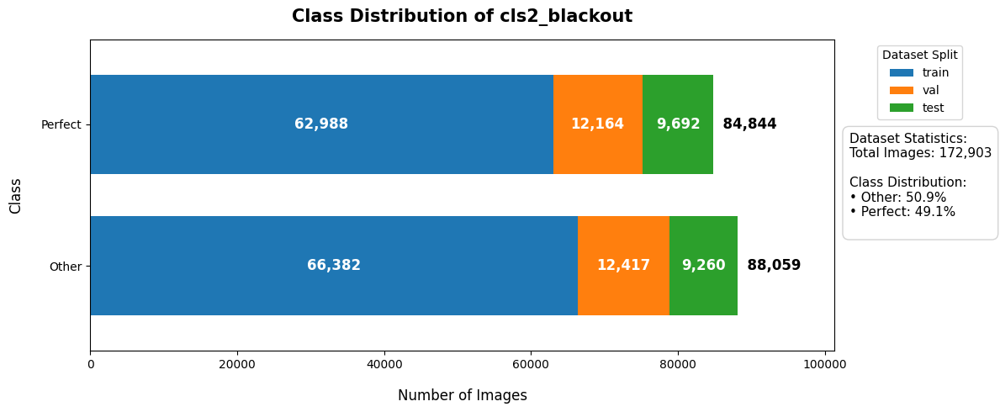

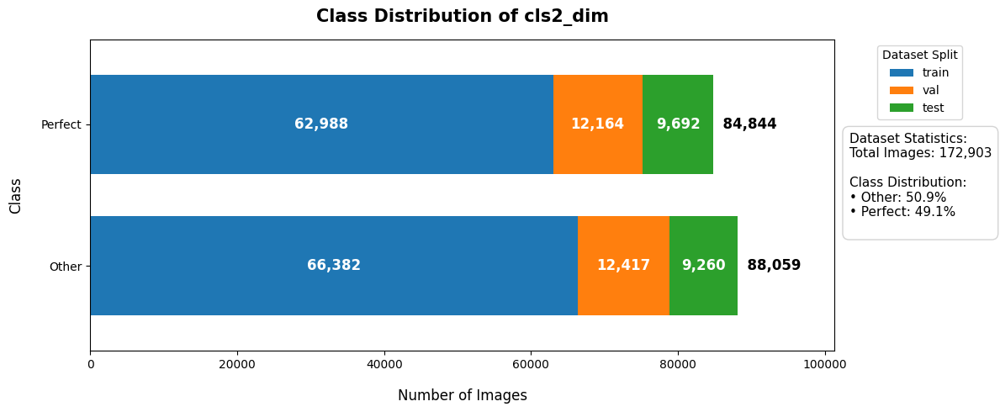

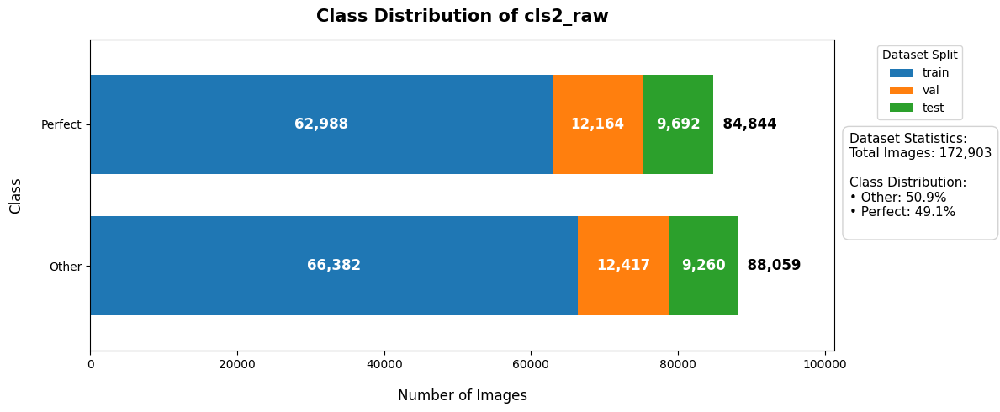

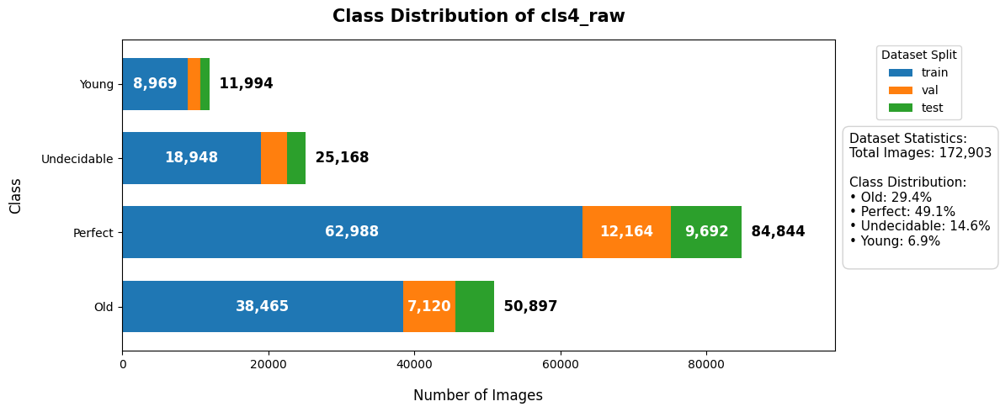

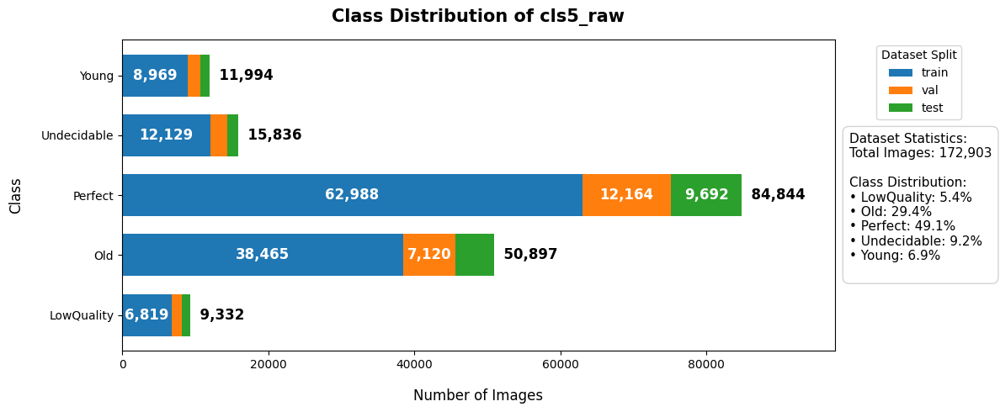

In [7]:
# plot_class_stat(cls_folders[0])
for dataset in sorted(cls_folders):
    plot_class_stat(dataset)

## Corpus

In [8]:
def plot_corpus(datasets_folder, header_text):
    target_total = 30
    cols = 10
    val_extension = {'.png'}
    
    cls_imgs = {}
    
    for split in ['train']:
        split_path = datasets_folder / split
        
        if not split_path.exists():
            continue
        
        for cls_dir in split_path.iterdir():
            if cls_dir.is_dir():
                cls_name = cls_dir.name
                
                if cls_name not in cls_imgs:
                    cls_imgs[cls_name] = []
                    
                for f in cls_dir.iterdir():
                    if f.is_file() and f.suffix.lower() in val_extension:
                        cls_imgs[cls_name].append(f)
                        
    num_cls = len(cls_imgs)
    if num_cls == 0:
        print("No classes or images found.")
        return
    
    base_samples = target_total // num_cls
    remainder = target_total % num_cls
    
    selected_paths = []
    selected_labels = []
    
    # random sample
    for i, (cls_name, paths) in enumerate(cls_imgs.items()):
        num_to_pick = base_samples + (1 if i < remainder else 0)
        num_to_pick = min(num_to_pick, len(paths))
        
        picked = random.sample(paths, num_to_pick)
        selected_paths.extend(picked)
        selected_labels.extend([cls_name] * len(picked))
        
    # calculate rows
    actual_total = len(selected_paths)
    rows = math.ceil(actual_total / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(16, 12))
    axes = axes.flatten()
    
    for i in range(len(axes)):
        if i < actual_total:
            img = Image.open(selected_paths[i])
            axes[i].imshow(img)
            axes[i].set_title(selected_labels[i], fontsize=8)
        
        axes[i].axis('off')

    fig.suptitle(header_text, fontsize=16, fontweight='bold', y=1)
    fig.patch.set_linewidth(2)
    fig.patch.set_edgecolor('black')
    plt.tight_layout()
    plt.show()
    print()

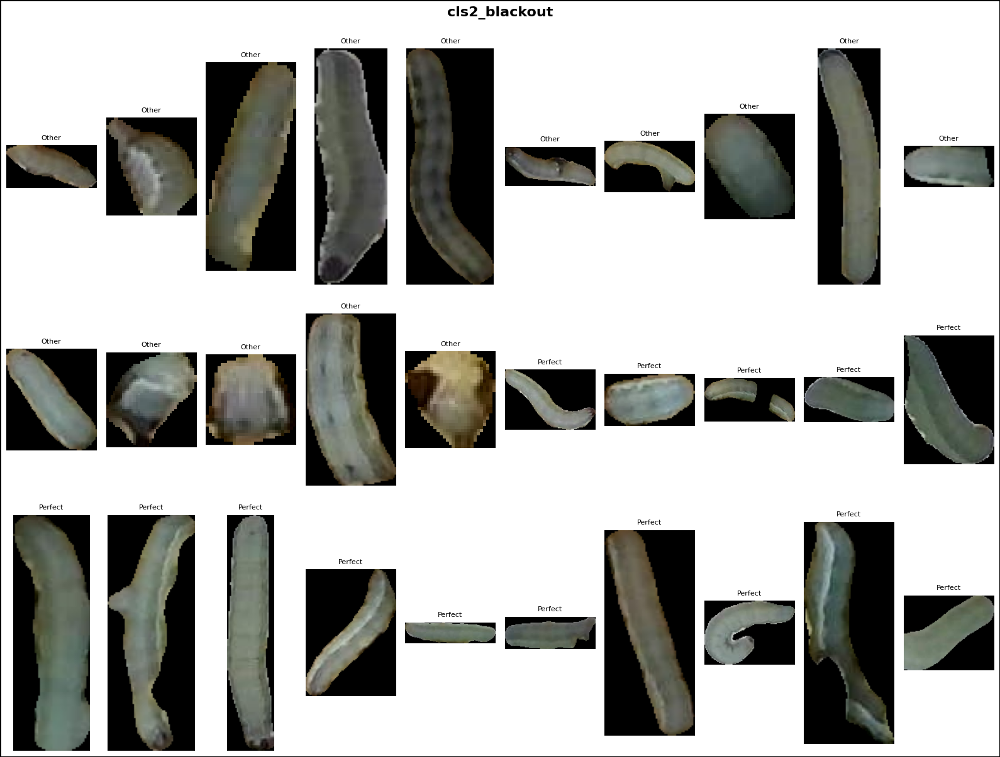

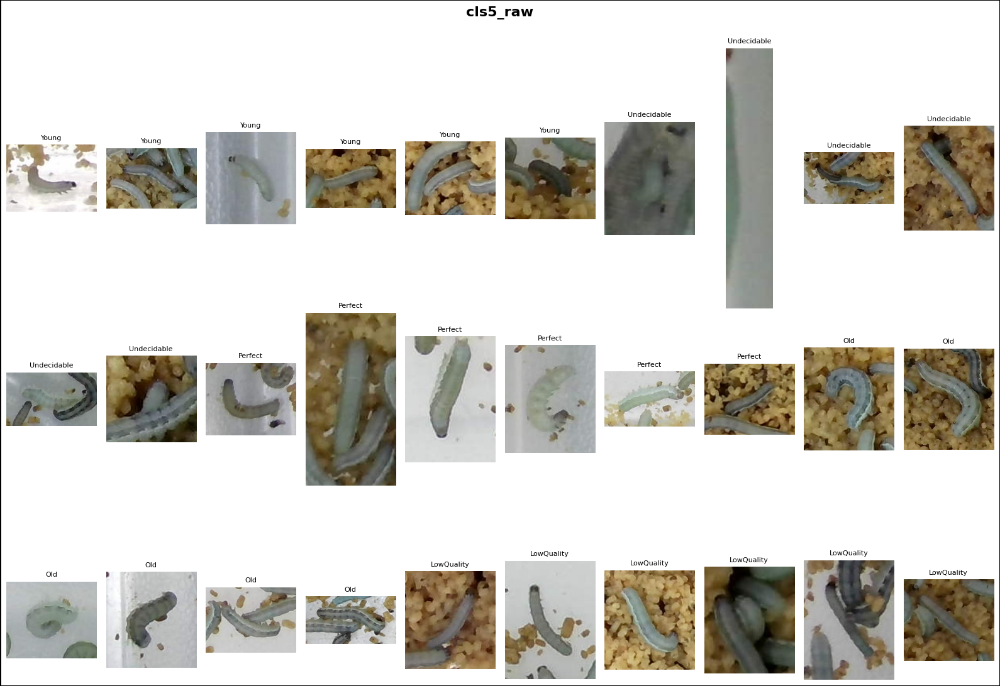

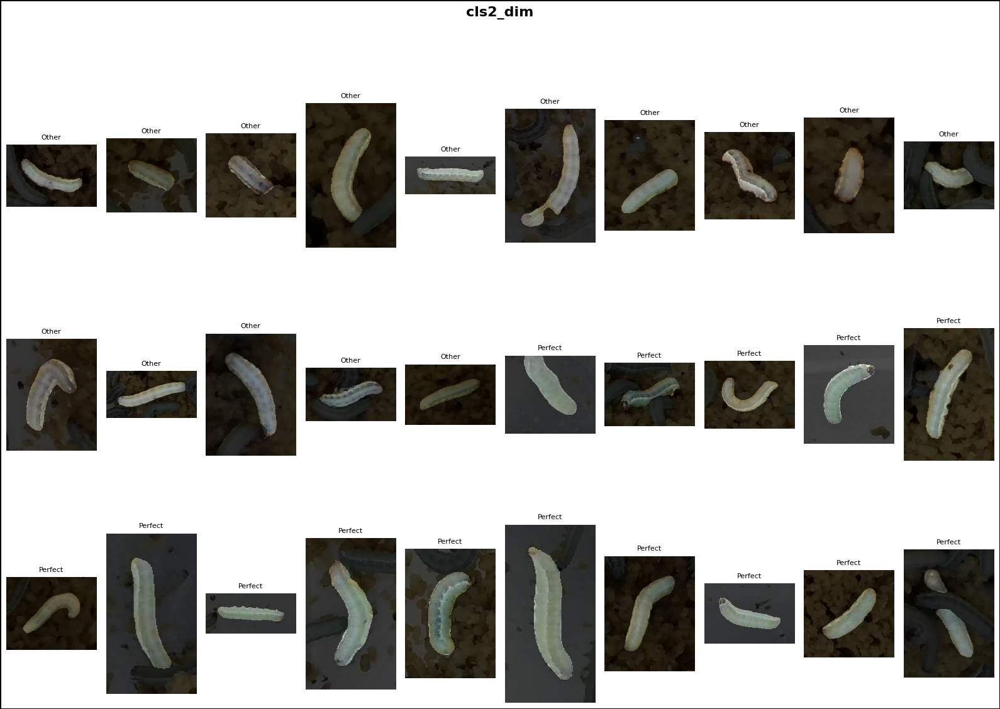

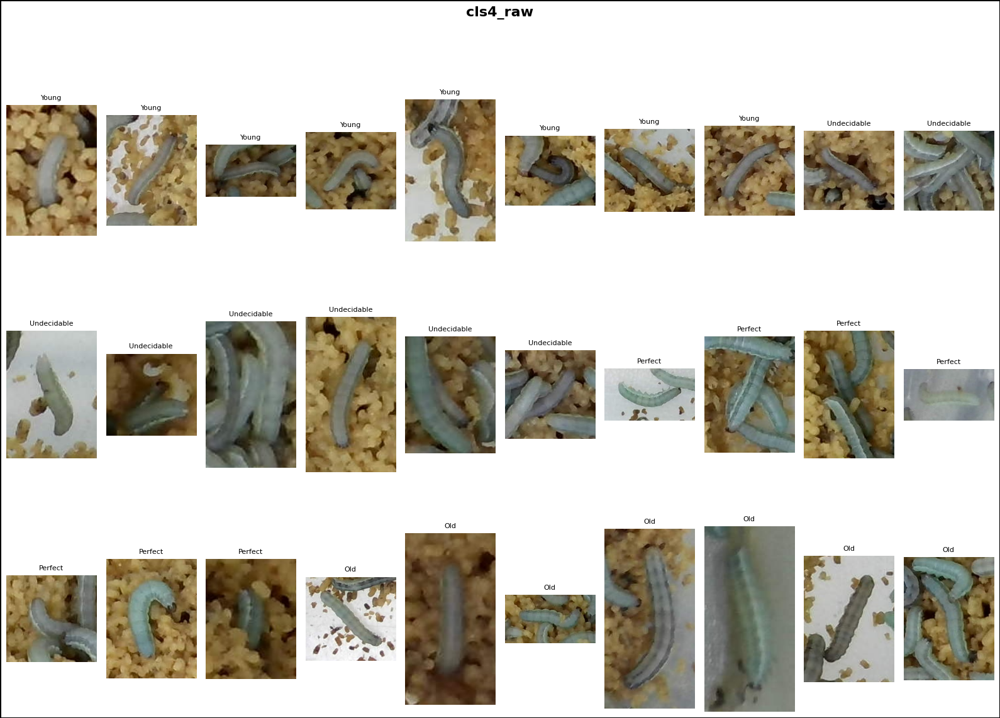

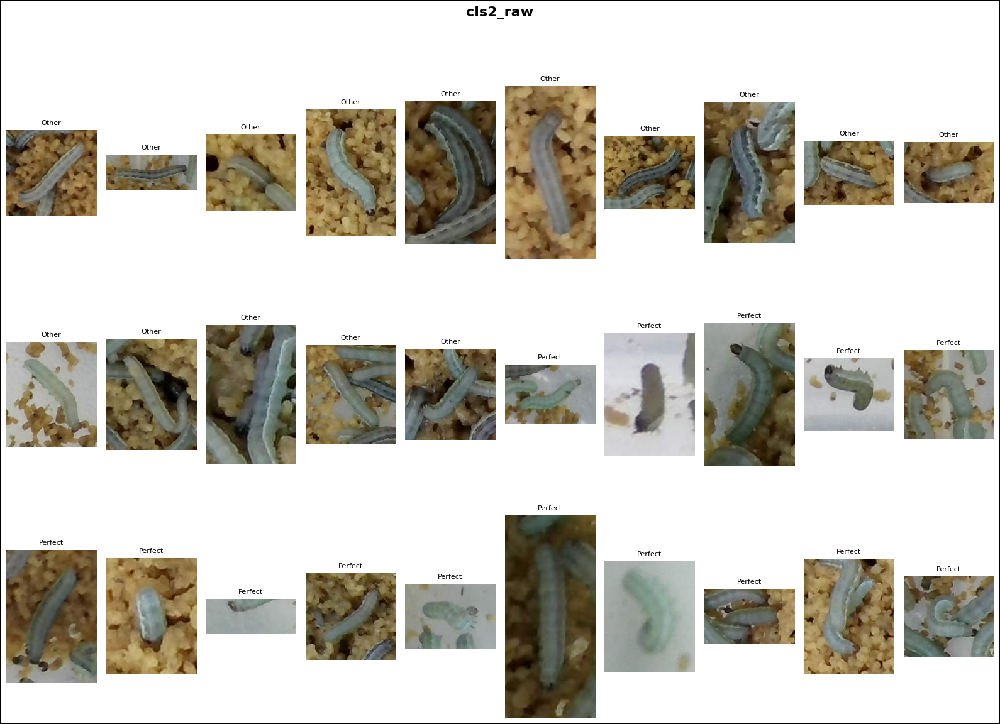

In [9]:
# plot_corpus(cls_folders[0])
for d in cls_folders:
    plot_corpus(d, d.name)

# Experiments

## Ranking

In [10]:
def plot_ranking(df, group='model', x_col='variant', metric='test_ap', hue_col='model', loc_cols=['variant', 'test_ap'], title='Models'):
    idx = df.groupby(group)[metric].idxmax()
    display(df.loc[idx, loc_cols].sort_values(by=metric, ascending=False))
    
    ranked = df.sort_values(metric, ascending=False).copy()

    if x_col == 'dataset_name':
        ranked['label'] = ranked['dataset_name'] + '\n(' + ranked['variant'] + ')'
        plot_x = 'label'
        rotation_deg = 0
    else:
        plot_x = x_col
        rotation_deg = 60
        
    fig, ax = plt.subplots(figsize=(16, 6))

    # draw bar
    sns.barplot(data=ranked, x=plot_x, y=metric, hue=hue_col, dodge=False, ax=ax, gap=0.1, palette='viridis' if x_col == 'dataset_name' else None)

    # write score
    for container in ax.containers:
        ax.bar_label(container, fmt='%.4f', fontsize=8, fontweight='bold', padding=3)

    ax.legend(title=hue_col, bbox_to_anchor=(1.01, 1), loc='upper left')

    # เอียง text
    plt.xticks(rotation=rotation_deg, ha='right' if rotation_deg > 0 else 'center', fontsize=9)

    # ตัดช่วงข้อมูล
    ymin, ymax = ranked[metric].min(), ranked[metric].max()
    ax.set_ylim(ymin - 0.02, ymax + 0.01)

    ax.set_xlabel(title, fontsize=12, labelpad=15)
    ax.set_ylabel(metric, fontsize=12, labelpad=15)
    ax.set_title(f'{title} Ranking', fontsize=15, fontweight='bold', pad=15)
    
    plt.tight_layout()
    plt.show()

In [11]:
exp_results = pd.read_excel(EXPERIMENT_LOG_PATH, sheet_name=0)

,variant,test_ap
14,convnext_large,0.8789
16,efficientnet_v2_m,0.8770
8,swin_v2_t,0.8729
27,resnet152,0.8706
3,yolo26l,0.8684
20,vit_l_16,0.8680


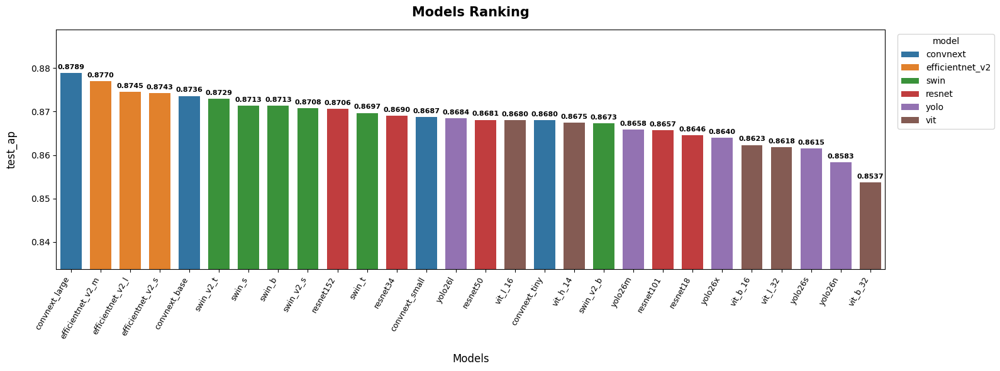

In [12]:
plot_ranking(exp_results)

# Review test results

In [13]:
def map_class(pred_path, label_path):
    pred = pd.read_csv(pred_path)
    label = pd.read_csv(label_path)

    def parse_filename(filename):
        if pd.isna(filename):
            return '', ''
        base = re.sub(r'\.(png|npy)$', '', str(filename), flags=re.IGNORECASE)
        match = re.search(r'^(.*?)[_]+(\d+)$', base)
        if match:
            stem = match.group(1).replace('__', '_').strip()
            obj_idx = match.group(2).lstrip('0') or '0'
            return stem, obj_idx
        return base.replace('__', '_').strip(), ''

    pred_parsed = pred['filename'].apply(parse_filename)
    pred['stem'] = [x[0] for x in pred_parsed]
    pred['obj_idx'] = [x[1] for x in pred_parsed]

    label_parsed = label['Filename'].apply(parse_filename)
    label['stem'] = [x[0] for x in label_parsed]
    label['obj_idx'] = [x[1] for x in label_parsed]
    label['actual_class'] = label['Class'].map(class_map)
    
    df = pd.merge(
        pred,
        label[['stem', 'obj_idx', 'actual_class']],
        on=['stem', 'obj_idx'],
        how='inner',
    )

    return df

In [14]:
def plot_img_pool(df, cols=10, sample_per_cls=30):
    df = df[(df['correct'] == 0) & (df['pred_label'] == POSITIVE)]
    
    for cls, group in df.groupby('actual_class'):
        img_paths = group['path'].tolist()[:sample_per_cls]
        total_img = len(img_paths)

        if total_img == 0:
            continue

        rows = math.ceil(total_img / cols)

        fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
        axes = np.array(axes).flatten()

        for i in range(len(axes)):
            if i < total_img:
                try:
                    img_path = img_paths[i]
                    img = Image.open(img_path).convert('RGB')
                    axes[i].imshow(img)
                    axes[i].axis('off')
                except Exception as e:
                    axes[i].text(0.5, 0.5, 'Error loading', ha='center', va='center', fontsize=8)
                    axes[i].axis('off')
            else:
                axes[i].axis('off')

        fig.suptitle(f'Ground Truth: {cls} (Predict: {POSITIVE})', fontsize=20, fontweight='bold', y=1)
        fig.patch.set_linewidth(2)
        fig.patch.set_edgecolor('black')
        plt.tight_layout()
        plt.show()


def plot_pred_histogram(df):
    fp_df = df[(df['correct'] == 0) & (df['pred_label'] == POSITIVE)]
    counts = fp_df['actual_class'].value_counts()
    total_counts = df['actual_class'].value_counts()

    temp_df = pd.DataFrame({'count': counts, 'total': total_counts})
    temp_df['count'] = temp_df['count'].fillna(0)
    temp_df['percent'] = (temp_df['count'] / temp_df['total']) * 100
    temp_df = temp_df.sort_values(by='percent', ascending=True)

    if POSITIVE in temp_df.index:
        temp_df = temp_df.drop(index=POSITIVE)
        
    ax = temp_df['percent'].plot(kind='barh', color='skyblue', figsize=(10, 6))
    
    plt.title('False Positive Breakdown', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Number of False Positives / Total Class Count', fontsize=12, labelpad=10)
    plt.ylabel('Classes', fontsize=12, labelpad=10)

    custom_labels = []
    for cls, row in temp_df.iterrows():
        count = row['count']
        total = row['total']
        percent = row['percent']
        if count > 0:
            custom_labels.append(f'{count:,.0f} / {total:,.0f} ({percent:.1f}%)')
        else:
            custom_labels.append(f'0 / {total:,.0f} (0.0%)')
        
    for container in ax.containers:
        ax.bar_label(container, labels=custom_labels, padding=5, fontsize=10, fontweight='bold')

    ax.set_xlim(right=ax.get_xlim()[1] * 1.25)
    plt.tight_layout()
    plt.show()
    

def analysis_err(df):
    plot_pred_histogram(df)
    plot_img_pool(df)

In [15]:
test_results_convl_2cr = map_class(TEST_PRED_CONVL_2CLS_RAW_PATH, LABEL_PATH)

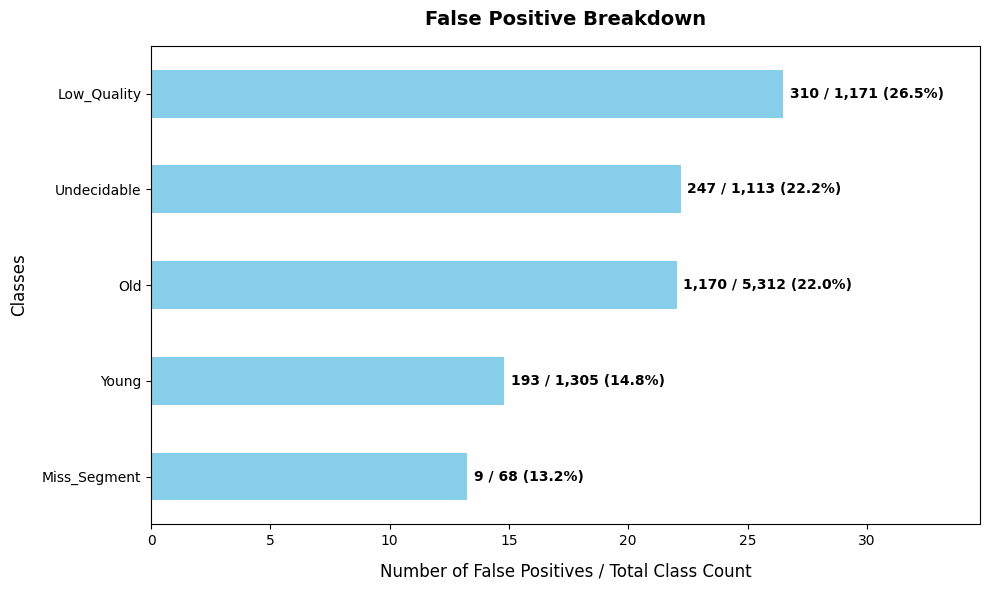

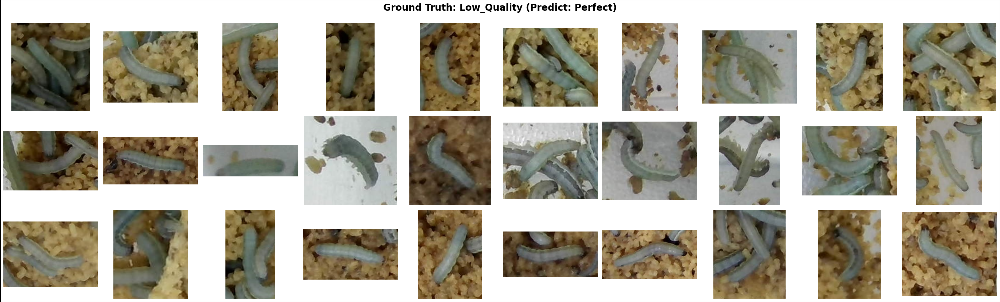

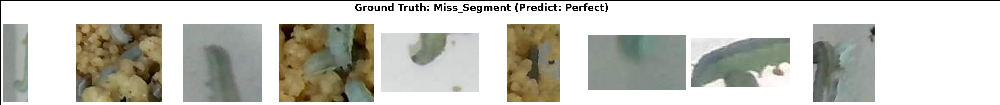

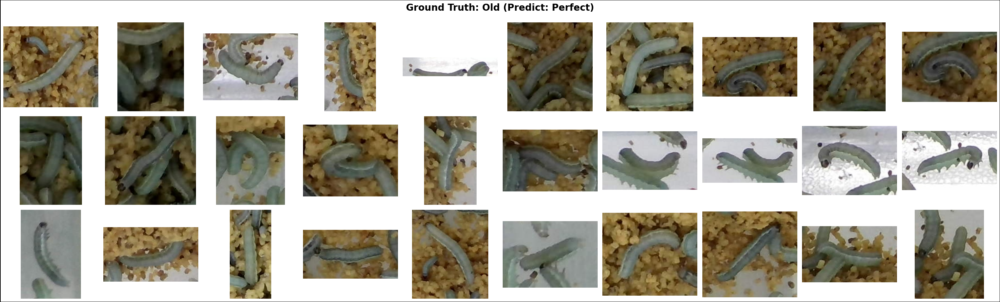

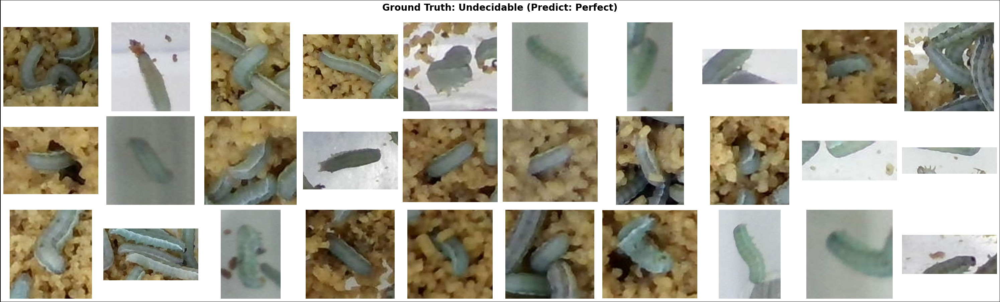

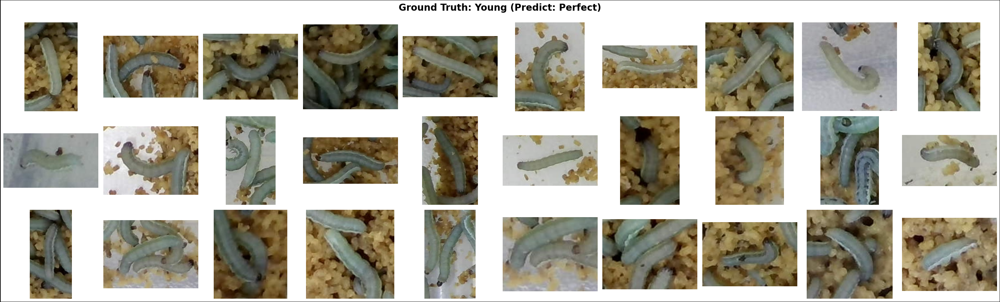

In [16]:
analysis_err(test_results_convl_2cr)

In [24]:
def plot_img_pool_select_class(df, cols=10, cls=POSITIVE, sample=30):
    df = df[df['true_label'] == cls]
    
    img_paths = df['path'].tolist()[:sample]
    total_img = len(img_paths)

    if total_img == 0:
        return

    rows = math.ceil(total_img / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
    axes = np.array(axes).flatten()

    for i in range(len(axes)):
        if i < total_img:
            try:
                img_path = img_paths[i]
                img = Image.open(img_path).convert('RGB')
                axes[i].imshow(img)
                axes[i].axis('off')
            except Exception as e:
                axes[i].text(0.5, 0.5, 'Error loading', ha='center', va='center', fontsize=8)
                axes[i].axis('off')
        else:
            axes[i].axis('off')

    fig.suptitle(f'Class: {cls}', fontsize=20, fontweight='bold', y=1)
    fig.patch.set_linewidth(2)
    fig.patch.set_edgecolor('black')
    plt.tight_layout()
    plt.show()

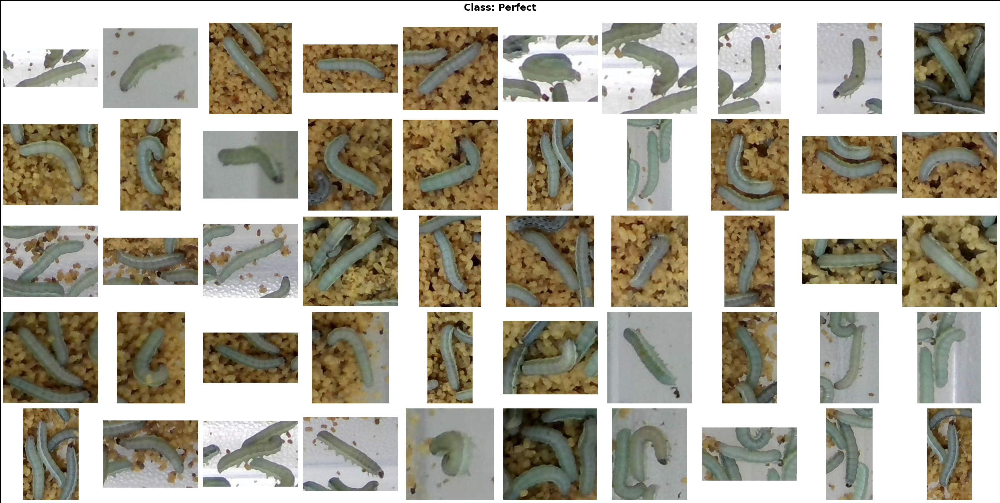

In [26]:
plot_img_pool_select_class(test_results_convl_2cr, sample=50)

# Background analysis

In [17]:
bg_df = pd.read_excel(BG_EXP_PATH, sheet_name=0)

,dataset_name,variant,test_ap
4,2class_dim,convnext_large,0.8814
6,2class_blackout,efficientnet_v2_m,0.8781
0,2class_raw,efficientnet_v2_m,0.8770


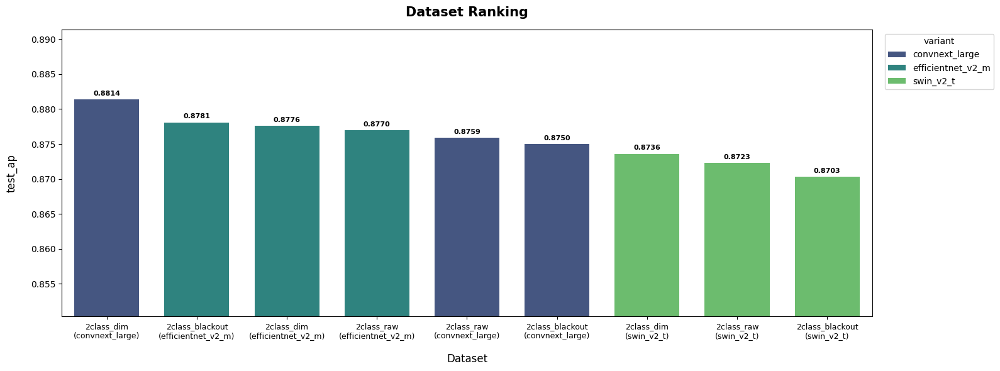

In [18]:
plot_ranking(bg_df, group='dataset_name', x_col='dataset_name', hue_col='variant', loc_cols=['dataset_name', 'variant', 'test_ap'], title='Dataset')

In [19]:
test_results_convl_2cd = map_class(TEST_PRED_CONVL_2CLS_DIM_PATH, LABEL_PATH)

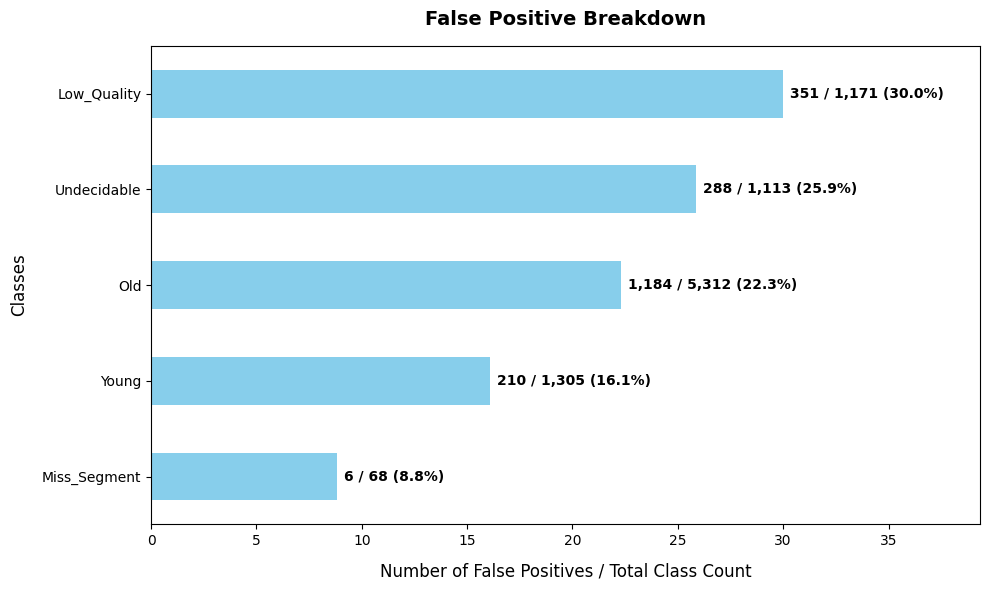

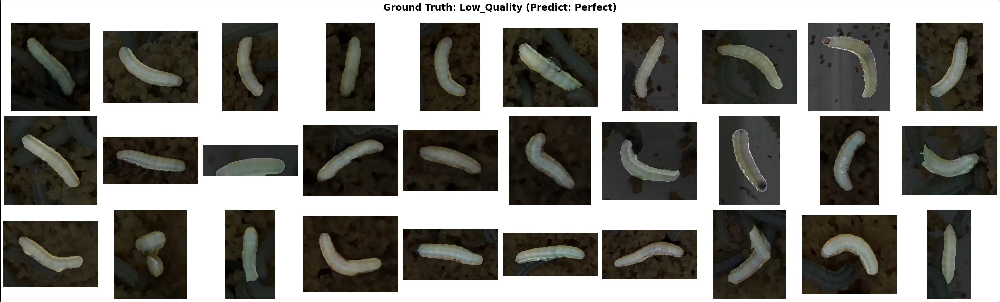

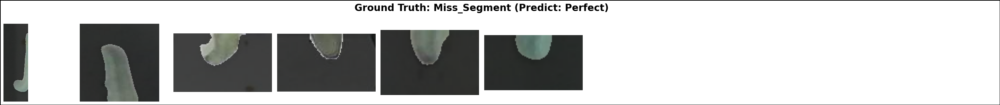

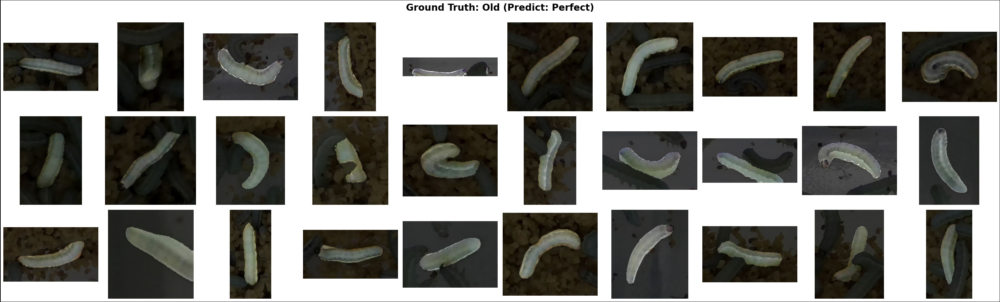

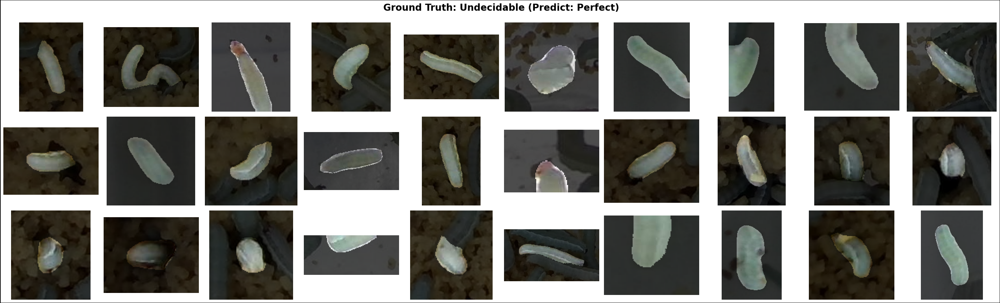

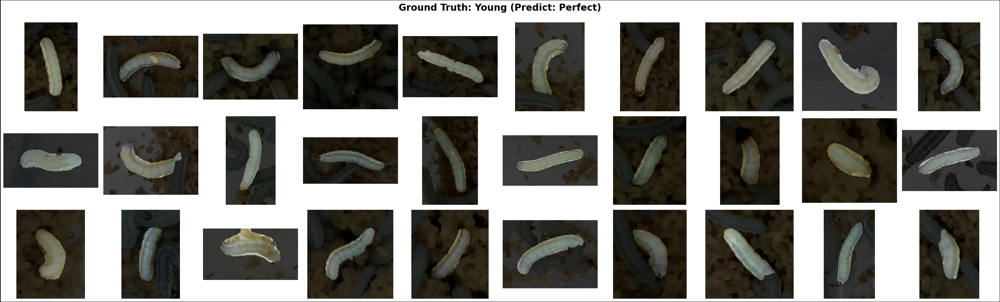

In [20]:
analysis_err(test_results_convl_2cd)

In [21]:
test_results_convl_2cr.head()

,index,path,filename,true_label,pred_label,correct,confidence,p_Other,p_Perfect,true_binary,...,outcome_r80,pred_r85,outcome_r85,pred_r90,outcome_r90,pred_r95,outcome_r95,stem,obj_idx,actual_class
0,0,/project/lt200264-saiwat/WormProject/data/rele...,worm-000003__0025.png,Other,Other,1,0.999979,0.999979,0.000021,non-Perfect,...,TN,non-Perfect,TN,non-Perfect,TN,non-Perfect,TN,worm-000003,25,Old
1,1,/project/lt200264-saiwat/WormProject/data/rele...,worm-000003__0027.png,Other,Other,1,0.999999,0.999999,0.000001,non-Perfect,...,TN,non-Perfect,TN,non-Perfect,TN,non-Perfect,TN,worm-000003,27,Old
2,2,/project/lt200264-saiwat/WormProject/data/rele...,worm-000003__0028.png,Other,Perfect,0,0.980129,0.019871,0.980129,non-Perfect,...,FP,Perfect,FP,Perfect,FP,Perfect,FP,worm-000003,28,Old
3,3,/project/lt200264-saiwat/WormProject/data/rele...,worm-000003__0045.png,Other,Other,1,0.999999,0.999999,0.000001,non-Perfect,...,TN,non-Perfect,TN,non-Perfect,TN,non-Perfect,TN,worm-000003,45,Old
4,4,/project/lt200264-saiwat/WormProject/data/rele...,worm-000003__0053.png,Other,Perfect,0,0.982151,0.017849,0.982151,non-Perfect,...,FP,Perfect,FP,Perfect,FP,Perfect,FP,worm-000003,53,Young
